In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import re
import os



In [5]:
dir_path = r"C:\Users\hwilson23\Documents\GitHub\collagen_3D_quantification"

filelist = [
    f for f in os.listdir(dir_path)
    if "current_final_dataframe_byslice_pos" in f
    and "trackmate" in f
]

# =========================
# LOAD FILES
# =========================
all_frames = []
for f in filelist:
    df = pd.read_csv(os.path.join(dir_path, f))

    # Drop exact column names
    DROP_COLS = [
        'TotalImageArea', 'distance3d', 'neighbor3d',
        'bin_num3d', 'roi', 'type'
    ]
    df = df.drop(DROP_COLS, axis=1, errors='ignore')

    # Drop columns matching any substring pattern
    #DROP_PATTERNS = ['distance3d', 'bin_num3d', 'slice_full']
    #pattern_cols = [c for c in df.columns if any(p in c for p in DROP_PATTERNS)]
    #df = df.drop(pattern_cols, axis=1, errors='ignore')

    # Drop pandas duplicate columns (fibercount.1, z_depth.2 etc.)
    #dupe_cols = [c for c in df.columns if re.search(r'\.\d+$', c)]
    #df = df.drop(dupe_cols, axis=1, errors='ignore')
    
    #df['concentration'] = df['image_name'].str.extract(r"(\d+mgml)")
    if 'position' not in df.columns:
        pos_match = re.search(r'pos_(\d+)', f, flags=re.IGNORECASE)
        df['position'] = int(pos_match.group(1)) if pos_match else np.nan
    all_frames.append(df)


combined = pd.concat(all_frames, ignore_index=True)
combined["position"] = combined["position"].astype("Int64")
combined["slice_id"] = combined["slice"].astype(str) + "_" + combined["position"].astype(str)



# =========================
# ID VARS — build dynamically from what actually exists
# =========================
CANDIDATE_ID_VARS = ["image_name", "slice_id", "position", "timepoint", "concentration","cell"]
id_vars = [c for c in CANDIDATE_ID_VARS if c in combined.columns]
print("ID VARS FOUND:", id_vars)

# =========================
# MASK CLASSIFIER
# =========================
def get_mask(col):
    parts = col.lower().split("_")
    # Handle mean_/median_/std_/n_ naming: mean_a1_metric, mean_full_metric etc.
    if len(parts) >= 2 and parts[1] in ("r10", "r20", "r30", "full"):
        if parts[1] == "full":
            return "full"
        return parts[1]
    # Suffix-style naming: metric_a1, metric_full etc.
    if "r10" in parts:
        return "r10"
    elif "r20" in parts:
        return "r20"
    elif "r30" in parts:
        return "r30"
    elif "full" in parts:
        return "full"
    return "full"

# =========================
# BUILD COLUMN GROUPS — whitelist only known feature prefixes
# =========================
FEATURE_PREFIXES = (
    "texture",        # catches TWOMBLI + texture3d
    "fibercount",
    "mean_",
    "median_",
    "std_",
    "n_",
    "z_depth",
    "Area",
    "Lacunarity",
    "Alignment",
    "Total",
              'Endpoints', 'HGU (microns)', 'Branchpoints', 'Box-Counting Fractal Dimension', '% High Density Matrix'          # if present
)
mask_groups = {"full": [], "r10": [], "r20": [], "r30": []}
skipped = []

for col in combined.columns:
    if col in id_vars:
        continue
    if not col.startswith(FEATURE_PREFIXES):
        skipped.append(col)
        continue
    mask_groups[get_mask(col)].append(col)

print("\nSKIPPED COLUMNS (not in any feature group):")
print(skipped)

print("\nCOLUMNS PER MASK GROUP:")
for mask, cols in mask_groups.items():
    print(f"  {mask}: {len(cols)} cols — sample: {cols[:3]}")

# =========================
# MELT
# =========================
long_frames = []
for mask_type, cols in mask_groups.items():
    if len(cols) == 0:
        continue
    temp = combined[id_vars + cols].melt(
        id_vars=id_vars,
        value_vars=cols,
        var_name="feature",
        value_name="value"
    )
    temp["mask_type"] = mask_type
    long_frames.append(temp)

long = pd.concat(long_frames, ignore_index=True)

'''
def clean_feature_name(col):
    parts = col.split("_")
    # Middle-mask style: mean_a1_metric → mean_metric
    if len(parts) >= 3 and parts[1].lower() in ("a1", "a2", "full", "cell"):
        return parts[0] + "_" + "_".join(parts[2:])
    # Suffix style: metric_a1 → metric
    for suffix in ("_full", "_a1", "_a2", "_cell", "_cell_masked"):
        if col.endswith(suffix):
            return col[: -len(suffix)]
    return col
'''
def clean_feature_name(col):
    tags = r'(?:_cell_masked|_r10_masked|_r20_masked|_r30_masked|_r10|_r20|_r30|_full|_cell)(?=_|$)'
    return re.sub(tags, '', col)

# =========================
# CLEAN — must happen BEFORE groupby
# =========================
long["value"] = pd.to_numeric(long["value"], errors="coerce")
long = long.dropna(subset=["value"])

long["feature"] = long["feature"].apply(clean_feature_name)

# Verify cleaned names look right
print("FEATURE SAMPLE AFTER CLEAN:")
print(long["feature"].unique()[:10])

# =========================
# AGGREGATE
# =========================
grouped = (
    long
    .groupby(
        ["position", "timepoint", "mask_type", "cell", "feature"],
        as_index=False
    )
    .agg(value=("value", "mean"))
)

# Verify all 4 masks present per feature
print("\nMASK CHECK FOR autoc:")
print(
    grouped[grouped["feature"].str.contains("autoc", na=False)]
    [["feature", "mask_type"]]
    .drop_duplicates()
    .sort_values("feature")
)

print("\nFEATURE EXAMPLES:")
print(grouped["feature"].unique()[:10])

print("\nMASK DISTRIBUTION:")
print(grouped["mask_type"].value_counts())



ID VARS FOUND: ['image_name', 'slice_id', 'position', 'timepoint', 'cell']

SKIPPED COLUMNS (not in any feature group):
['slice']

COLUMNS PER MASK GROUP:
  full: 65 cols — sample: ['texture3d_mean_full_inf2h', 'texture3d_mean_full_senth', 'texture3d_mean_full_homop']
  r10: 65 cols — sample: ['texture3d_mean_r10_inf2h', 'texture3d_mean_r10_senth', 'texture3d_mean_r10_homop']
  r20: 65 cols — sample: ['texture3d_mean_r20_inf2h', 'texture3d_mean_r20_senth', 'texture3d_mean_r20_homop']
  r30: 65 cols — sample: ['texture3d_mean_r30_inf2h', 'texture3d_mean_r30_senth', 'texture3d_mean_r30_homop']
FEATURE SAMPLE AFTER CLEAN:
['texture3d_mean_inf2h' 'texture3d_mean_senth' 'texture3d_mean_homop'
 'texture3d_mean_dissi' 'texture3d_mean_corrp' 'texture3d_mean_denth'
 'texture3d_mean_inf1h' 'texture3d_mean_maxpr' 'texture3d_mean_entro'
 'texture3d_mean_energ']

MASK CHECK FOR autoc:
                    feature mask_type
0      texture3d_mean_autoc      full
65     texture3d_mean_autoc       r10
1

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


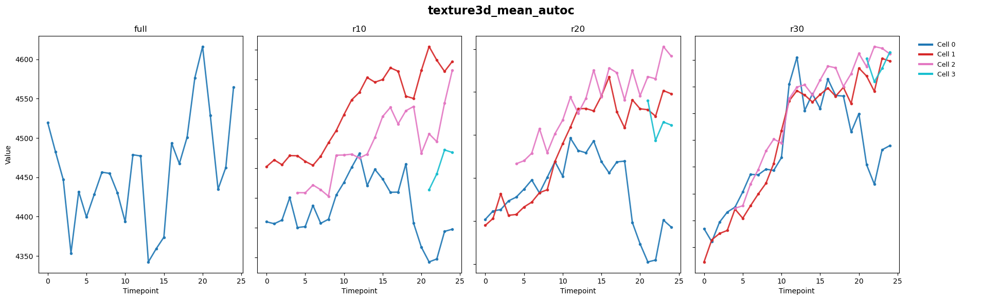

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


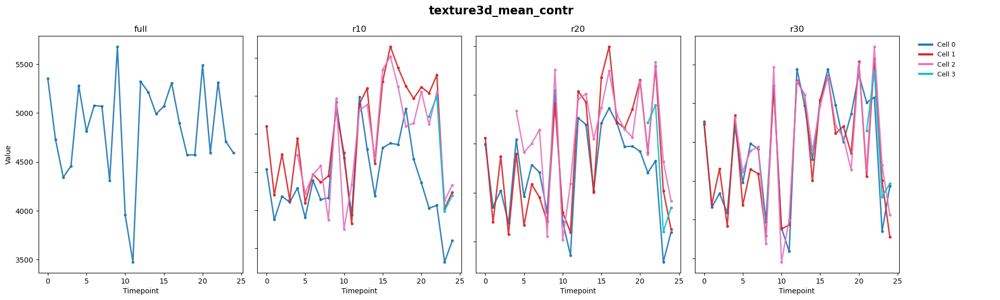

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


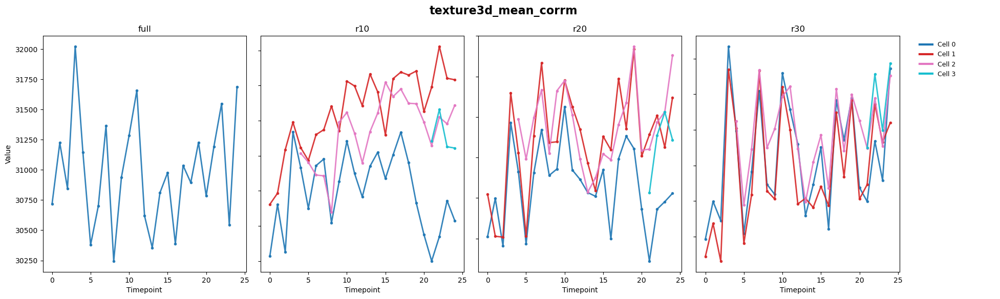

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


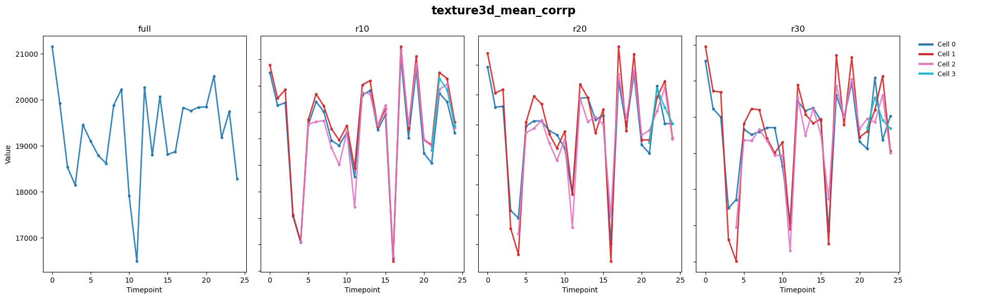

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


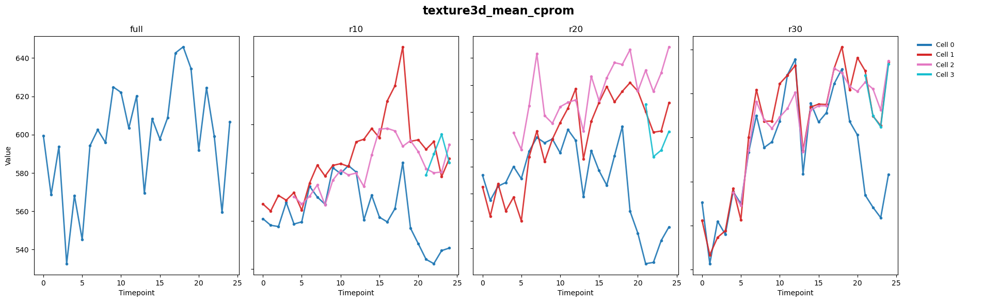

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


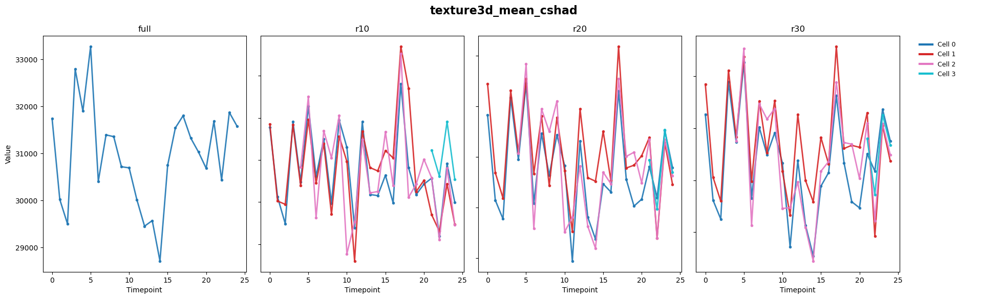

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


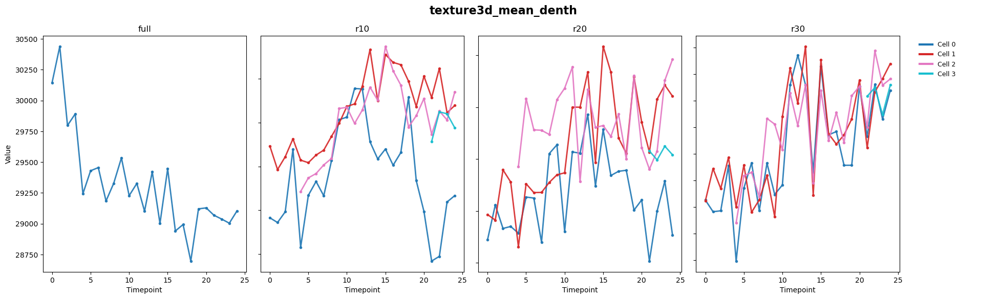

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


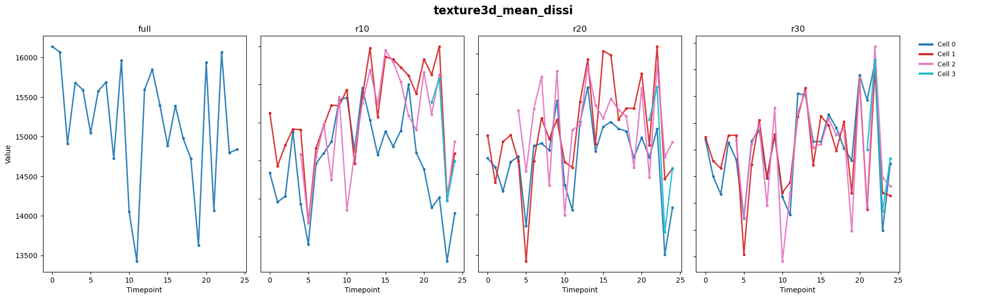

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


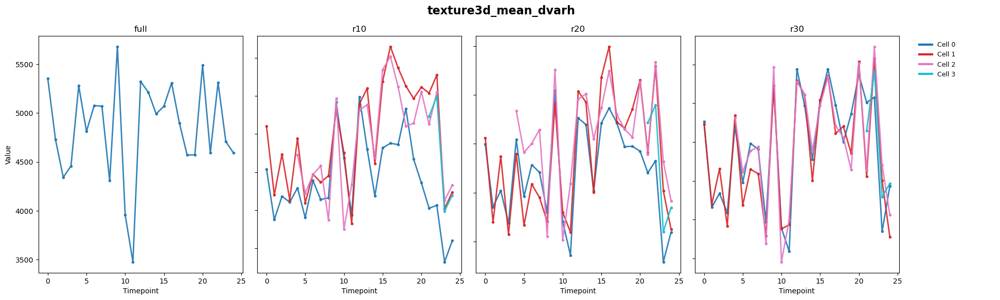

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


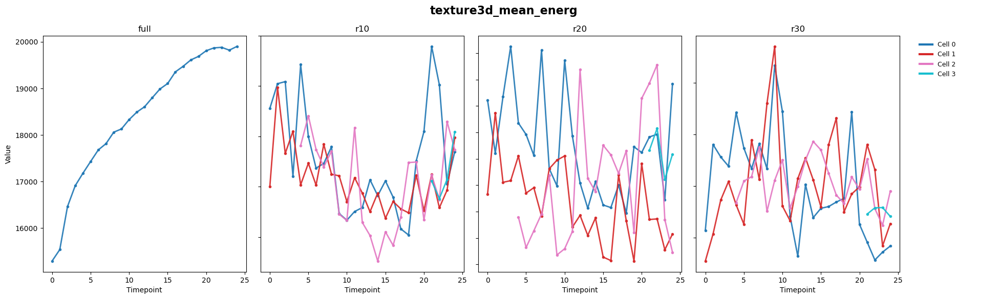

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


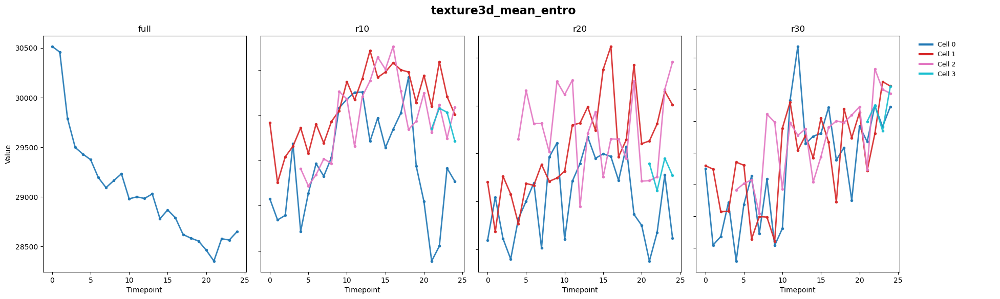

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


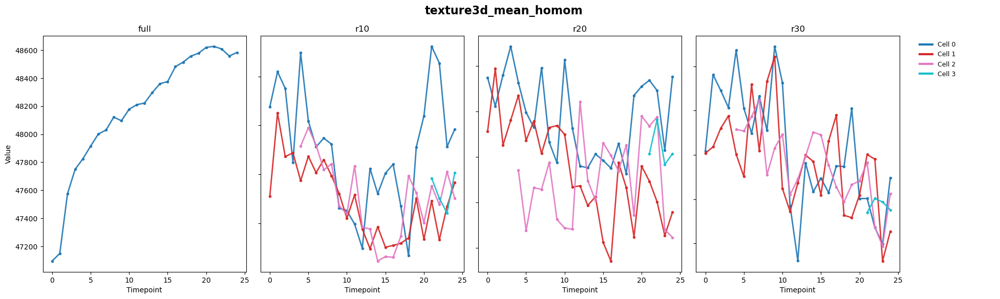

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


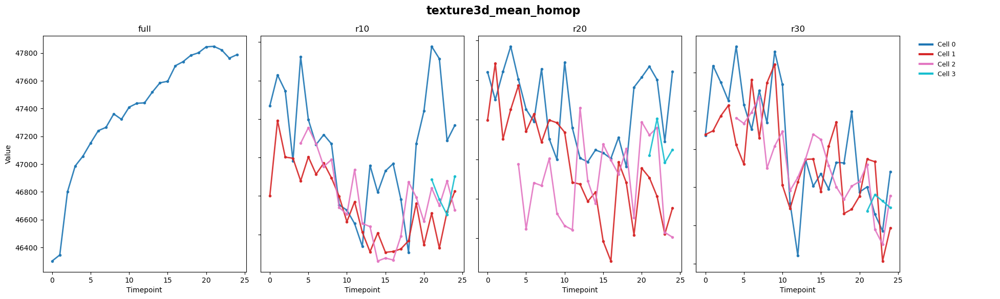

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


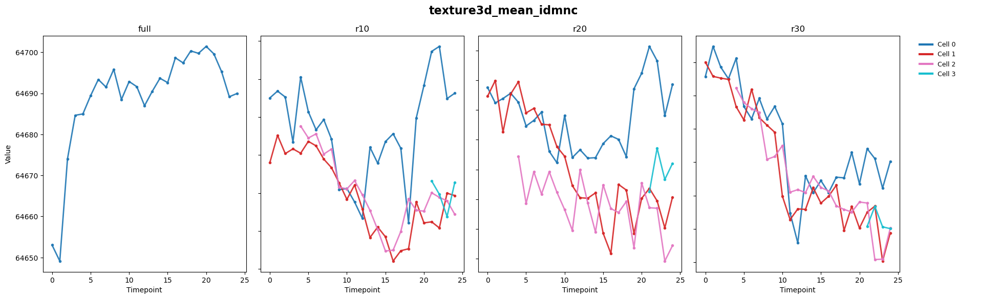

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


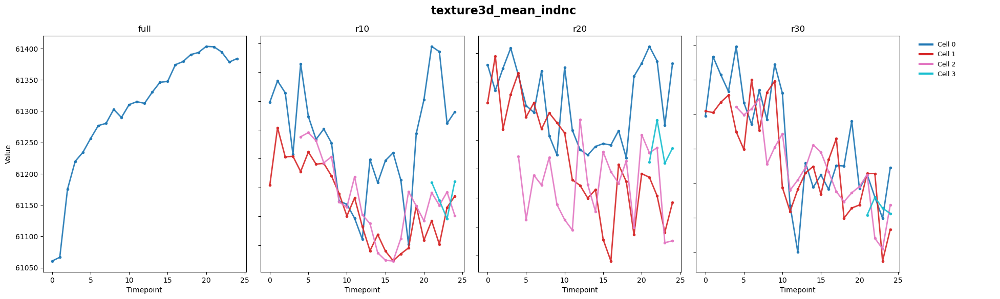

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


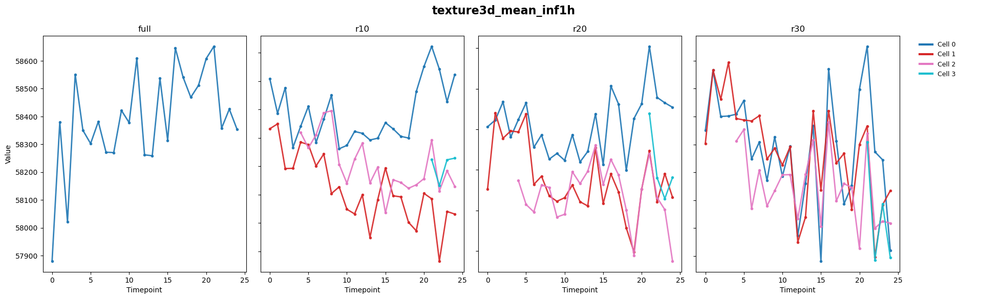

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


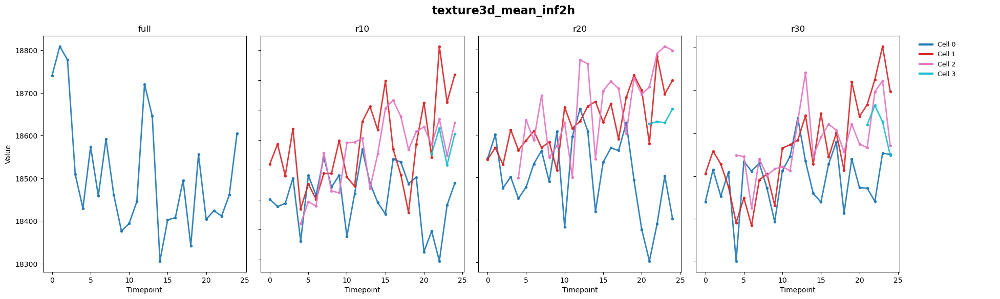

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


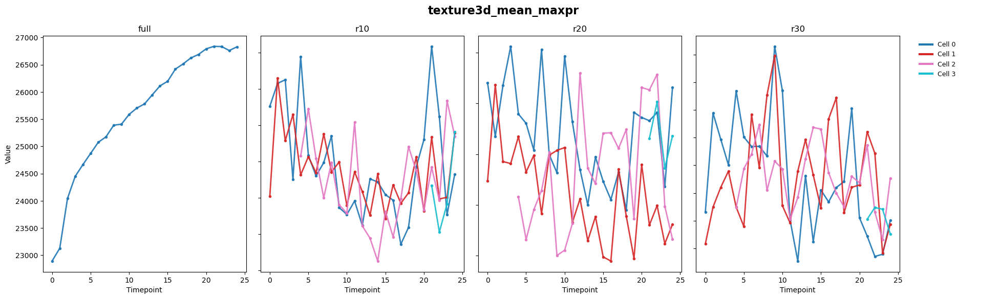

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


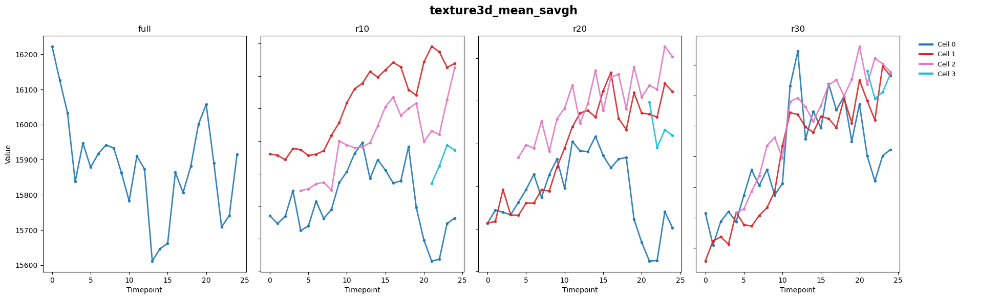

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


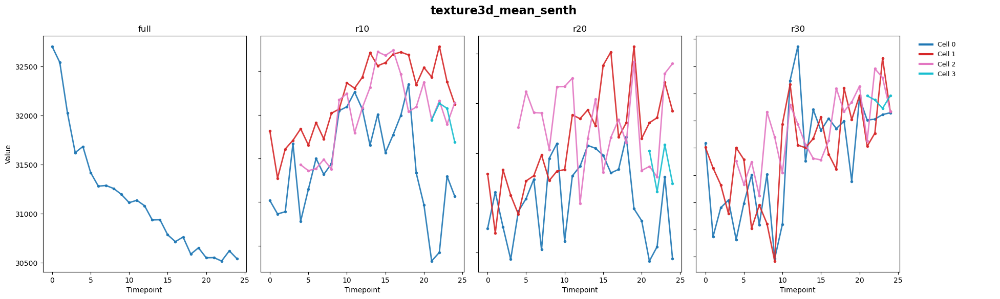

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


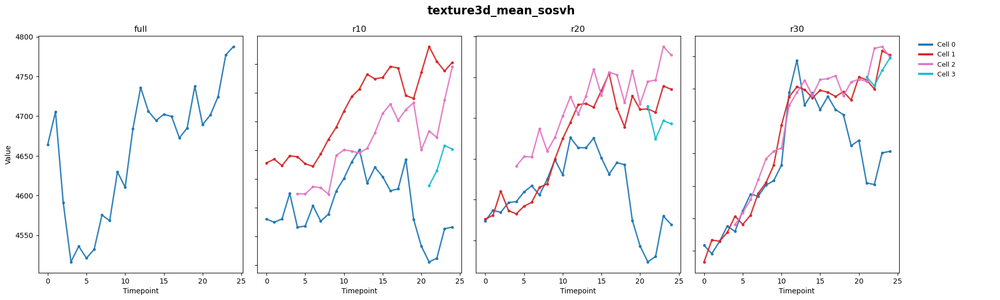

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


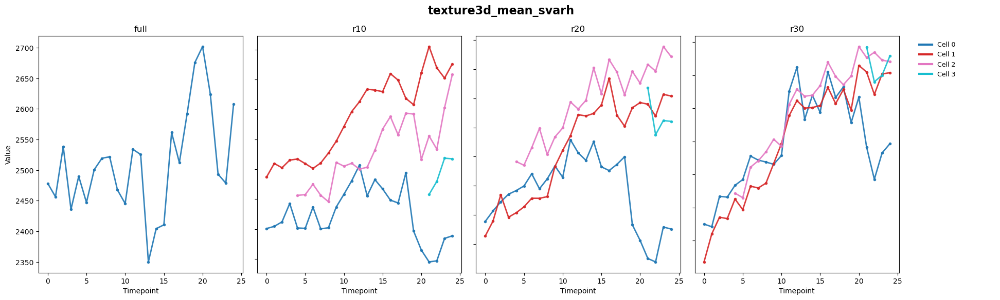

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


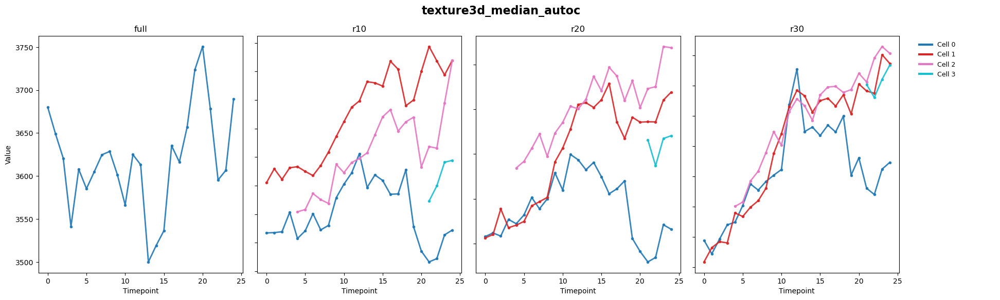

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


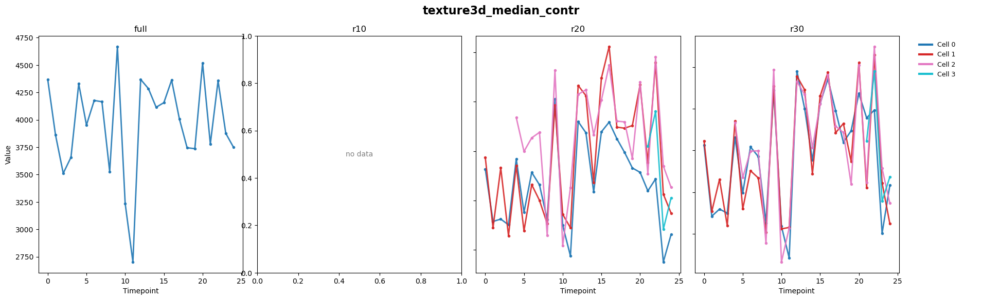

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


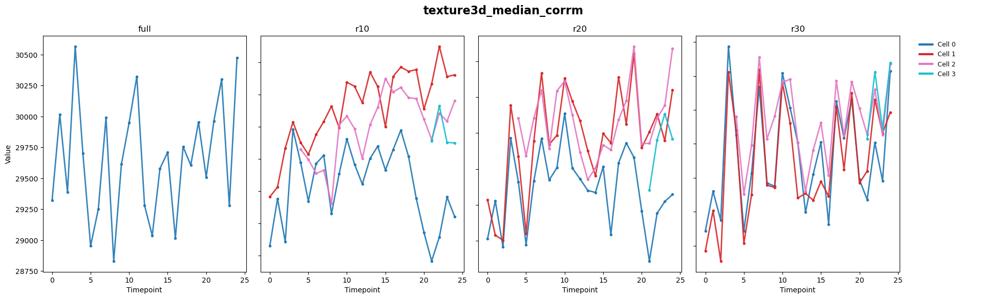

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


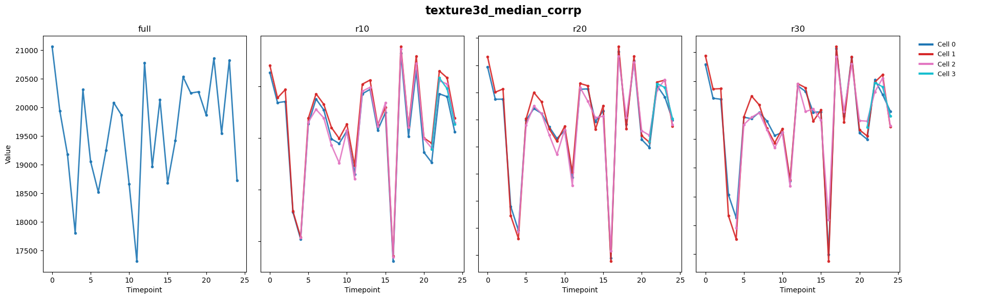

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


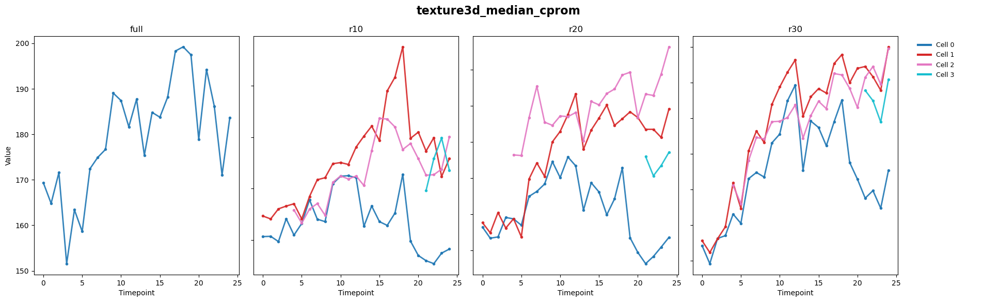

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


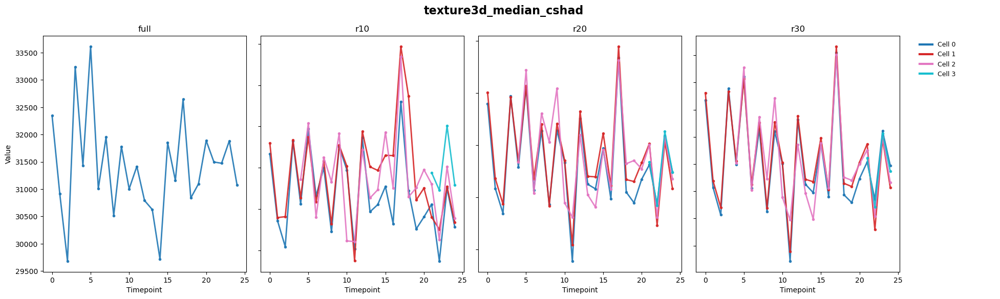

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


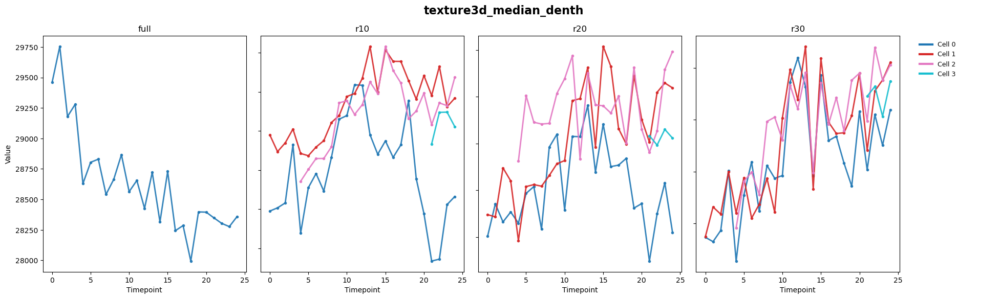

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


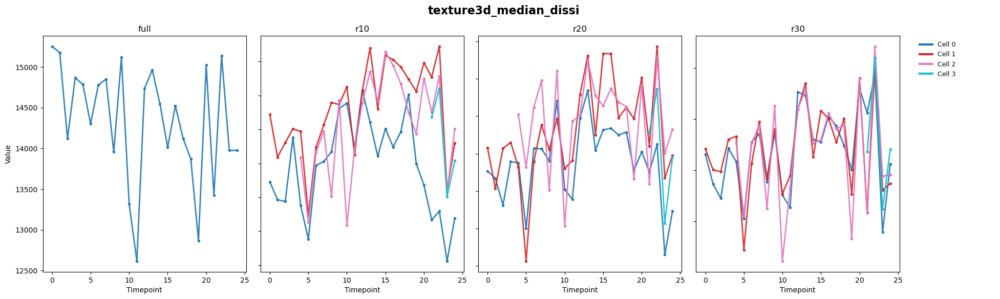

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


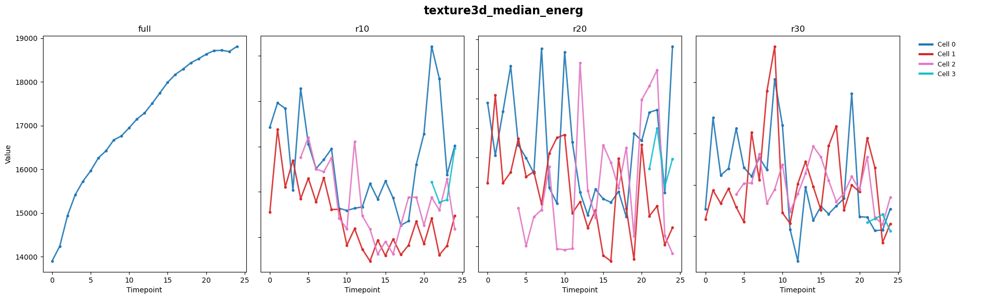

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


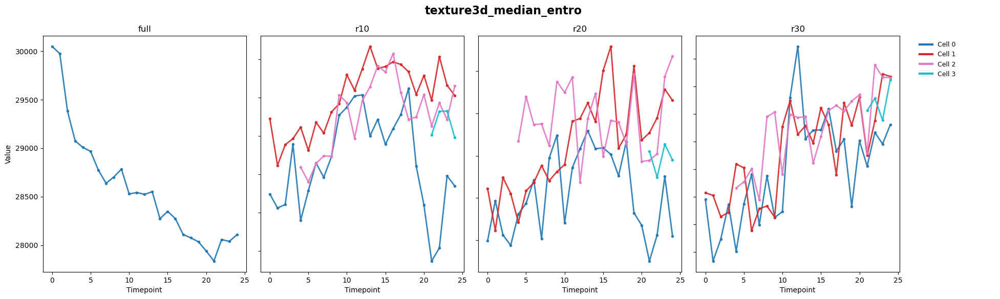

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


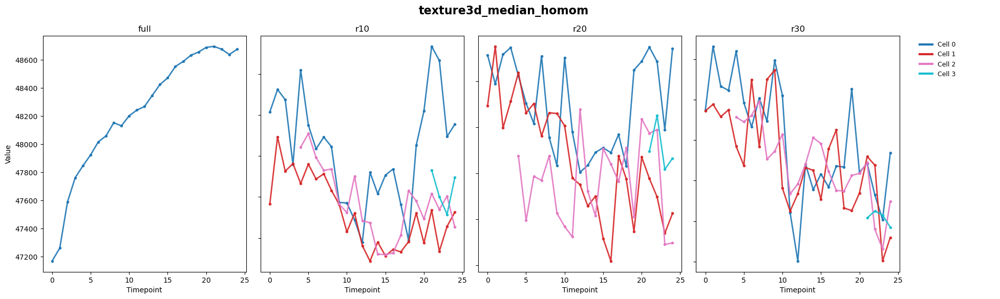

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


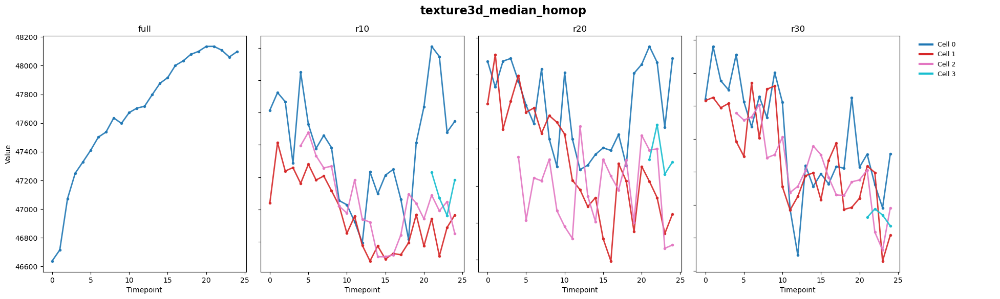

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


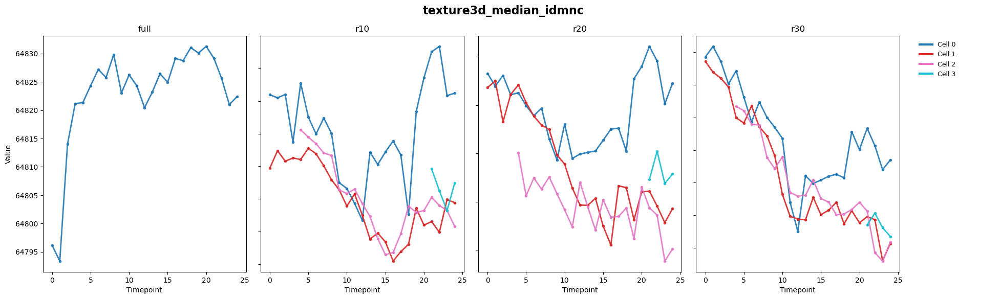

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


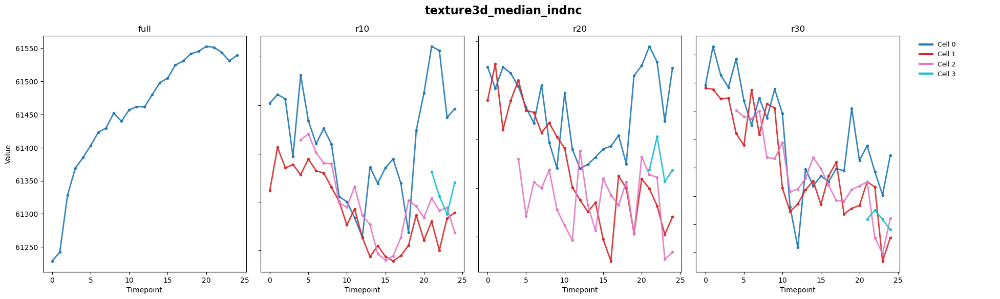

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


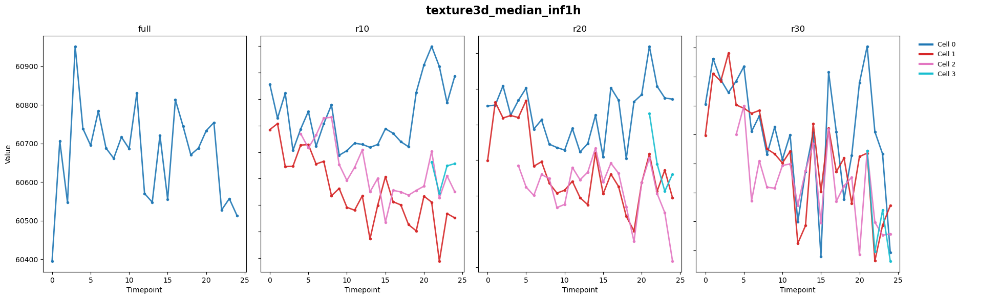

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


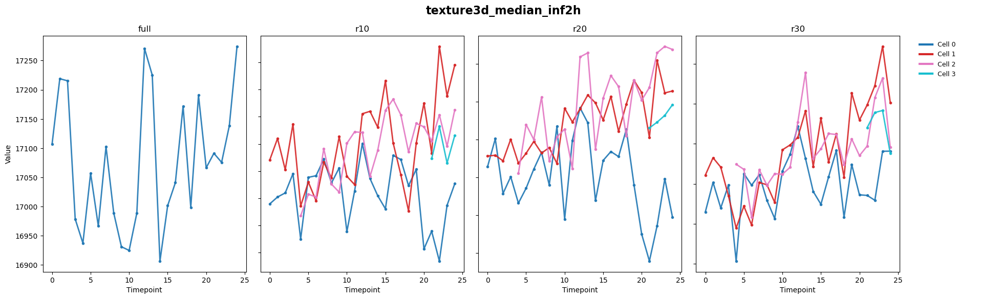

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


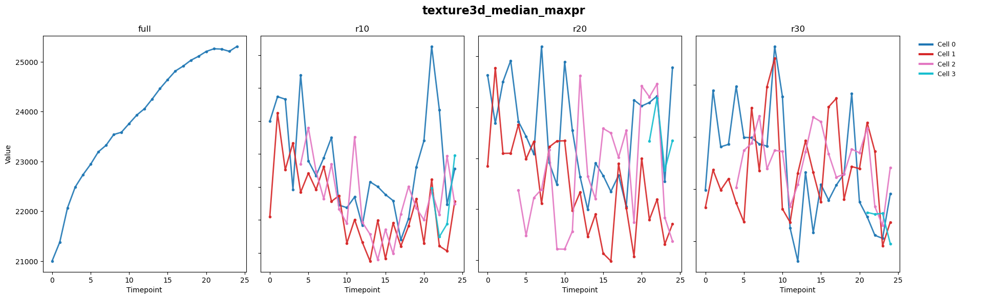

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


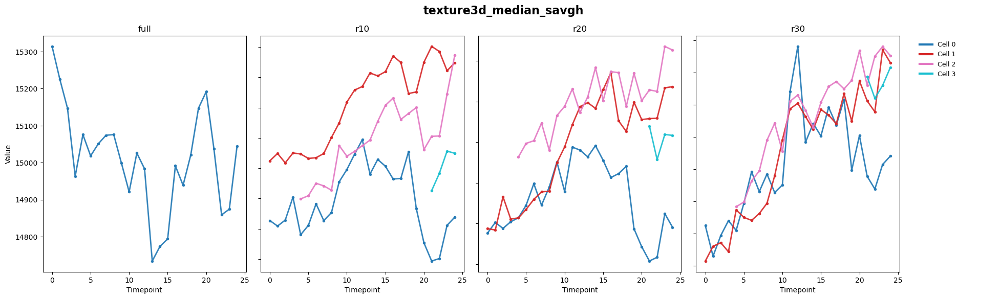

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


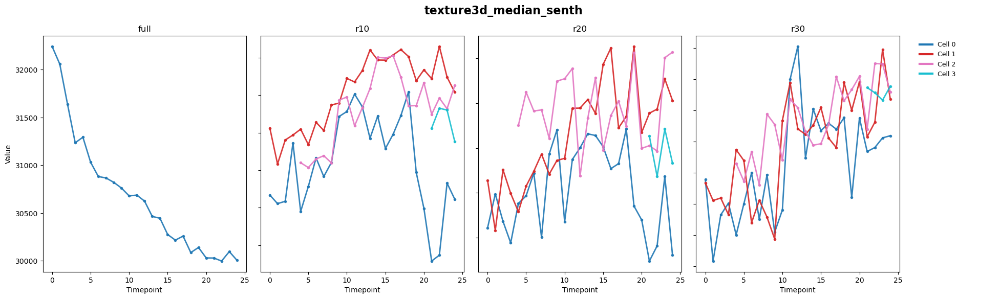

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


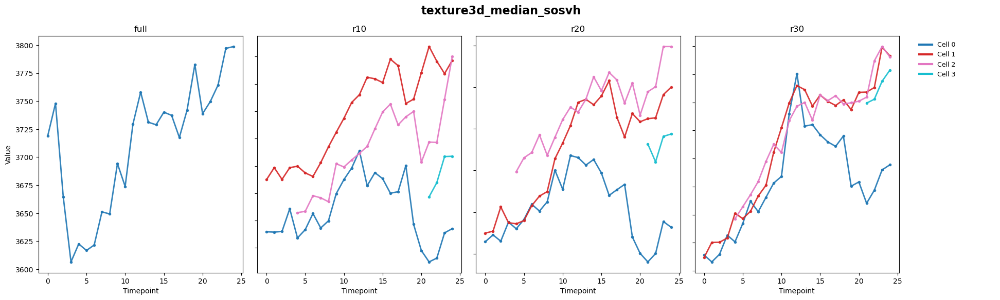

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


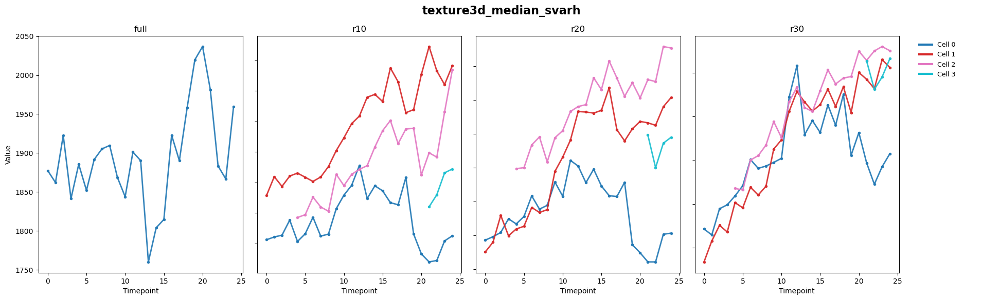

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


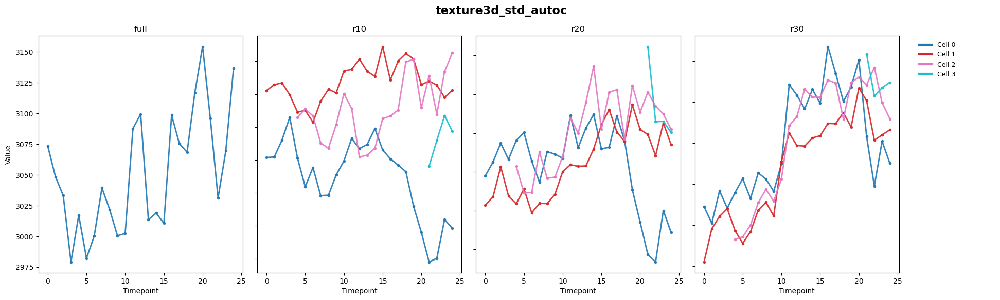

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


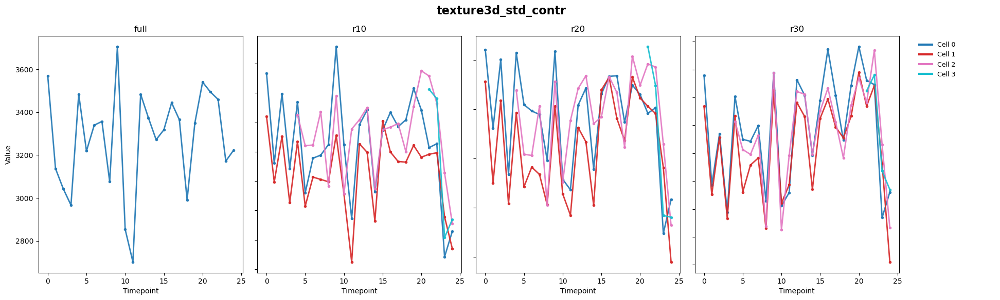

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


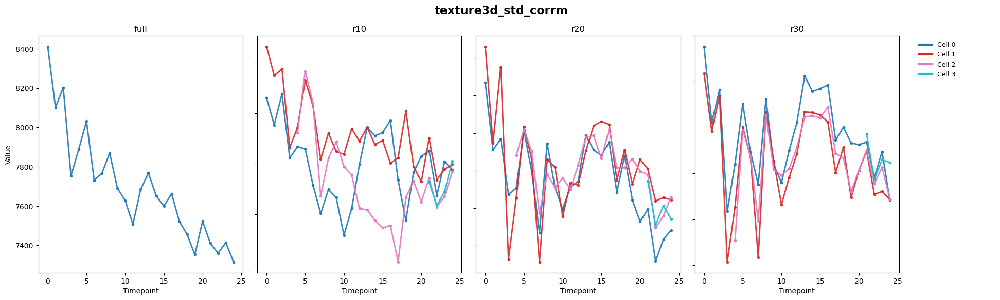

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


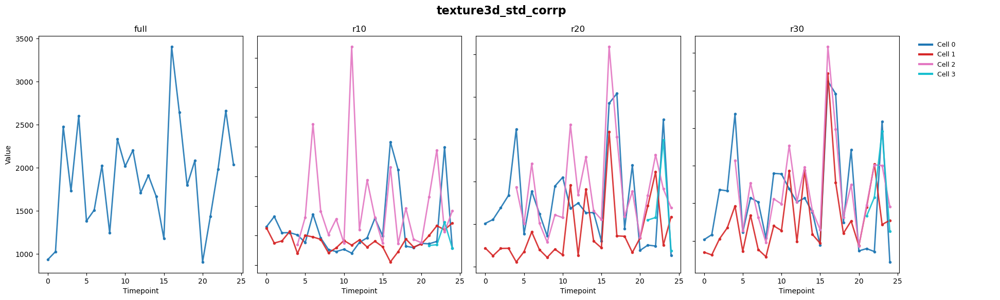

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


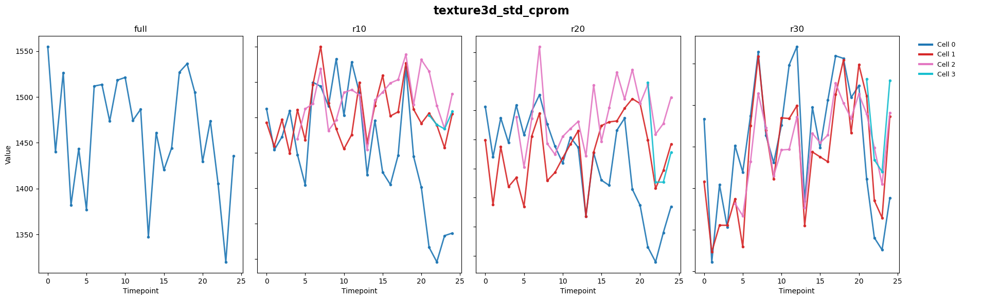

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


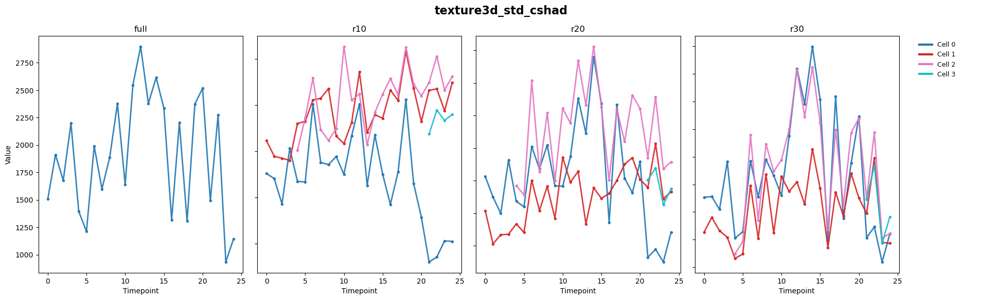

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


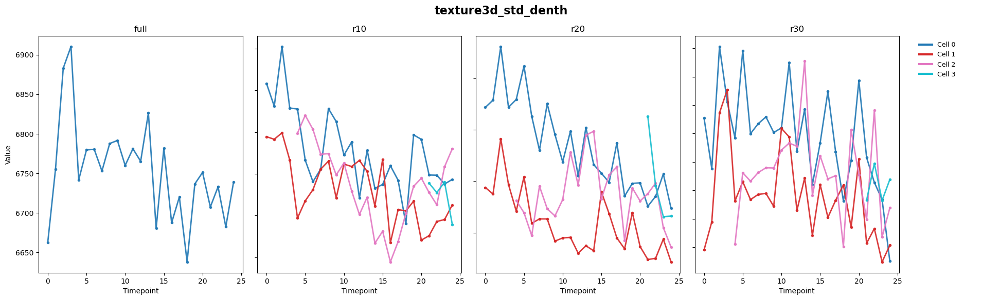

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


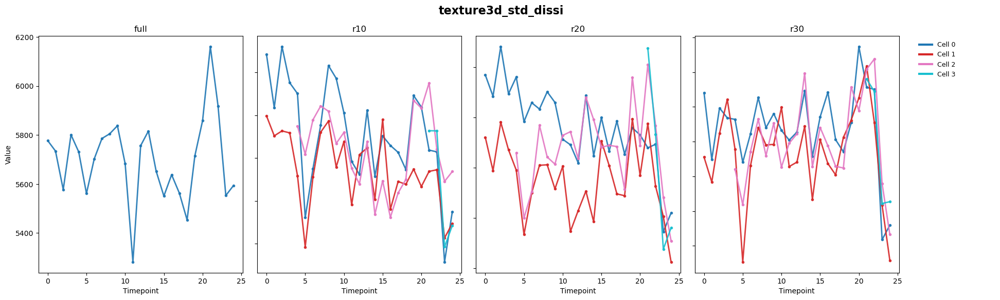

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


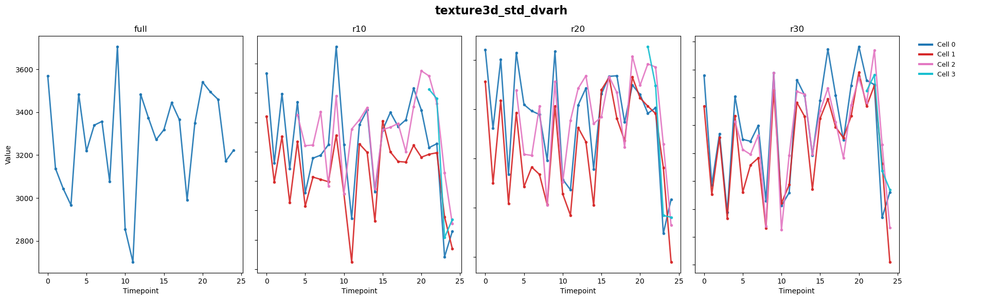

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


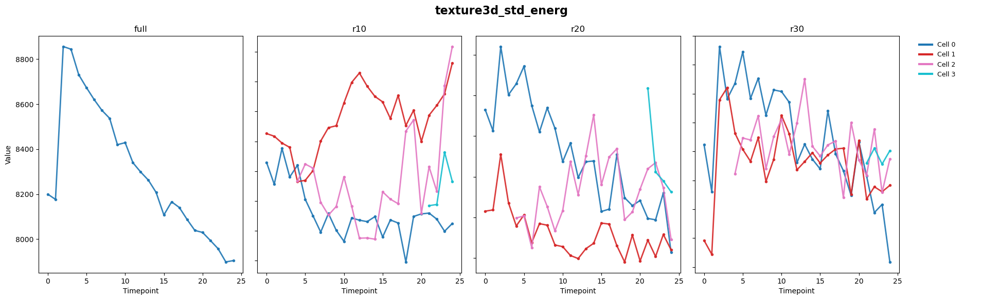

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


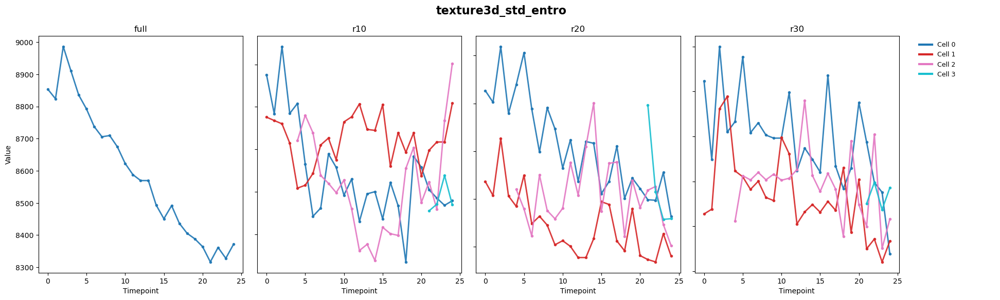

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


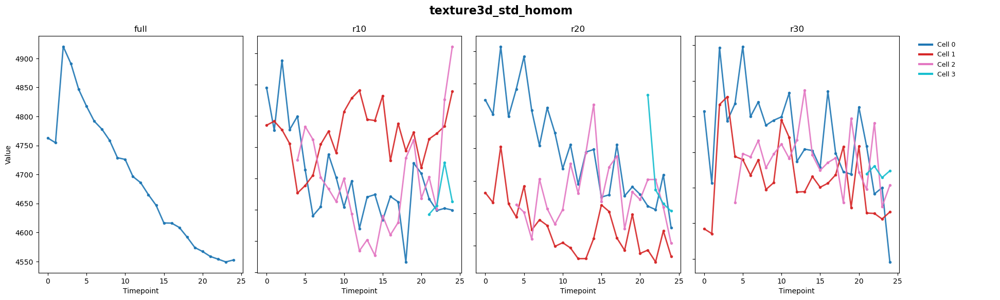

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


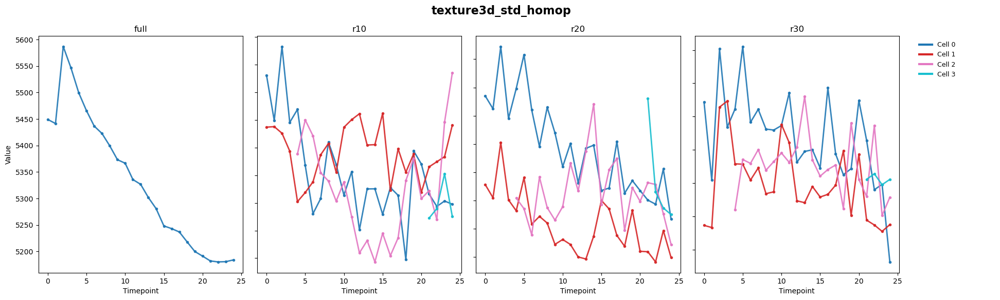

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


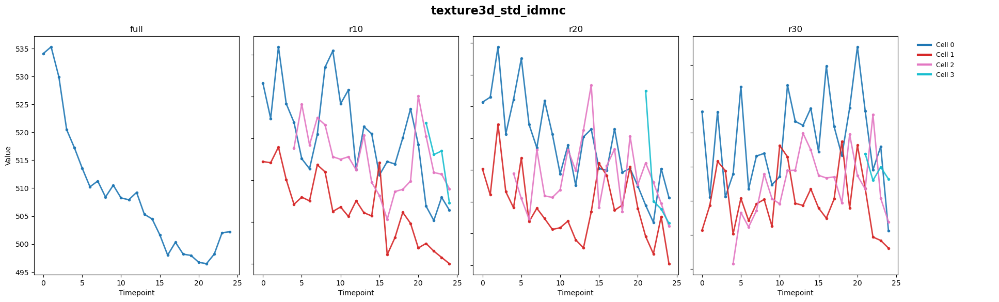

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


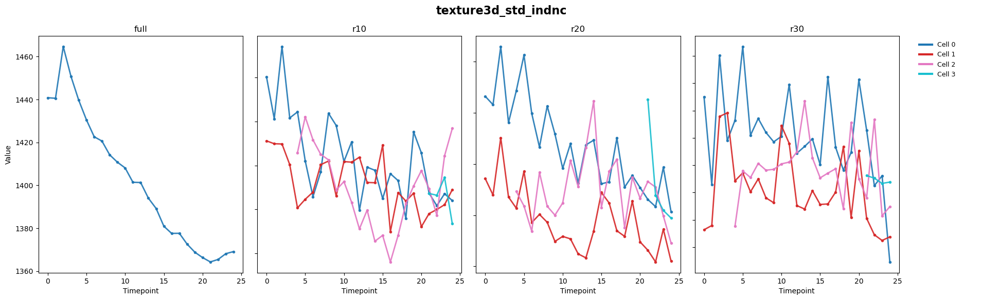

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


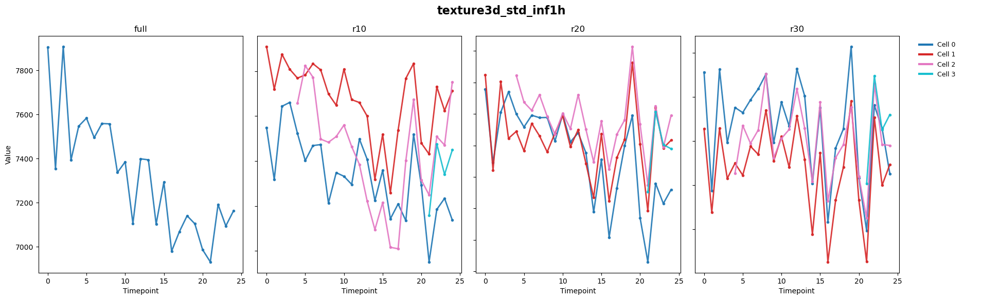

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


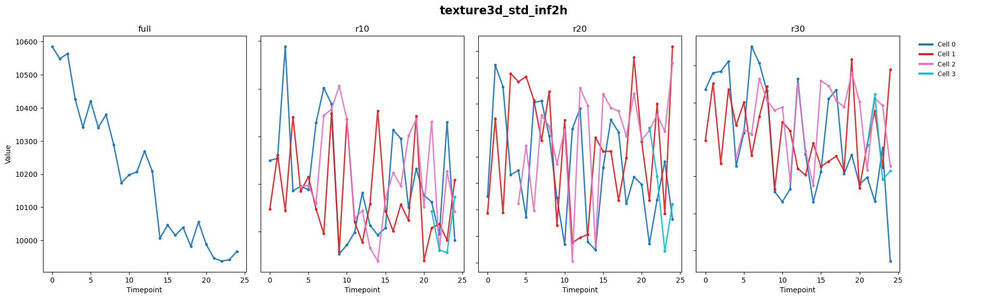

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


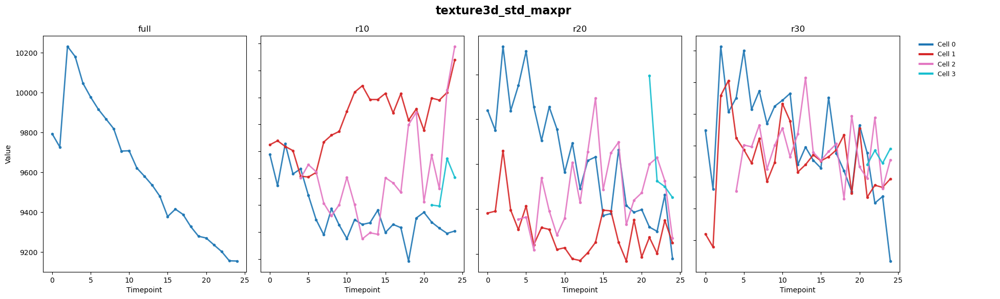

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


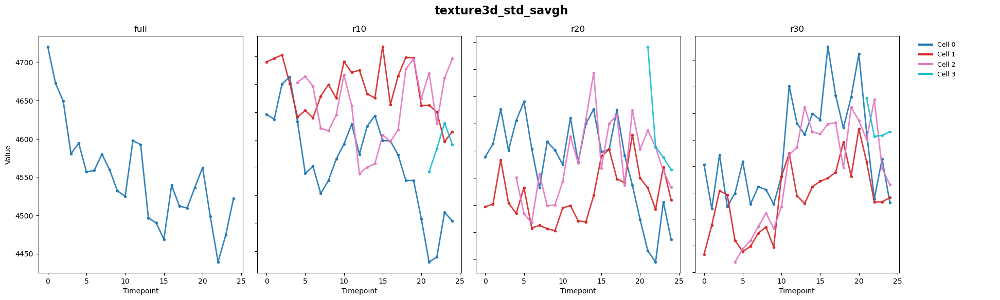

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


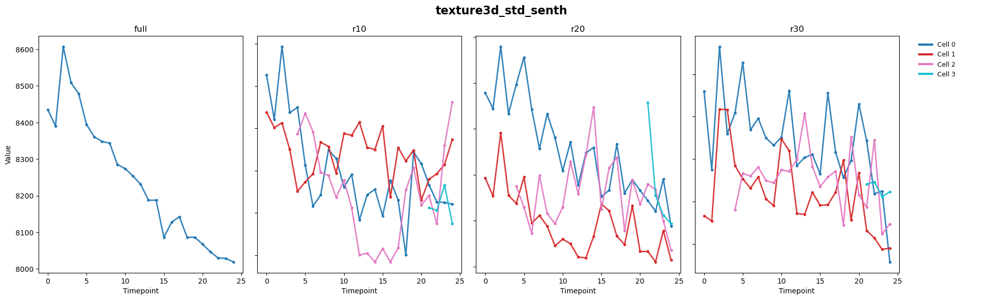

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


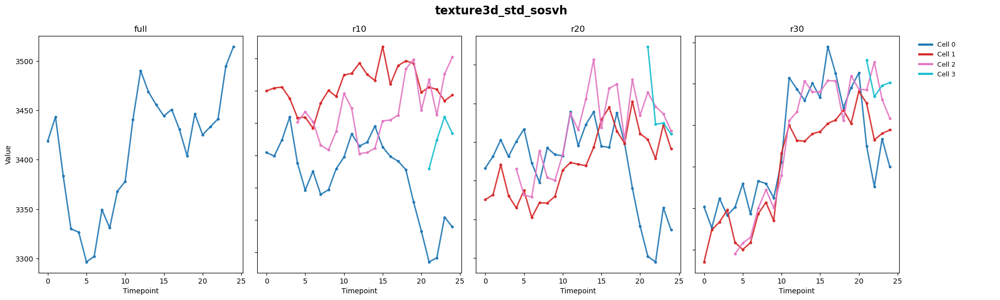

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


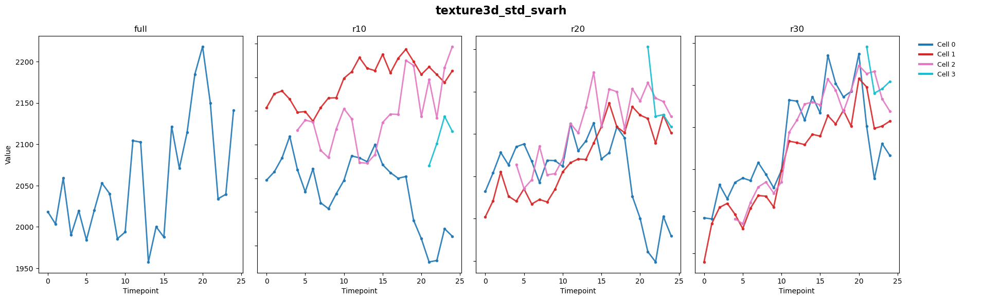

C:\Users\hwilson23\AppData\Local\Temp\ipykernel_25136\3258911540.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


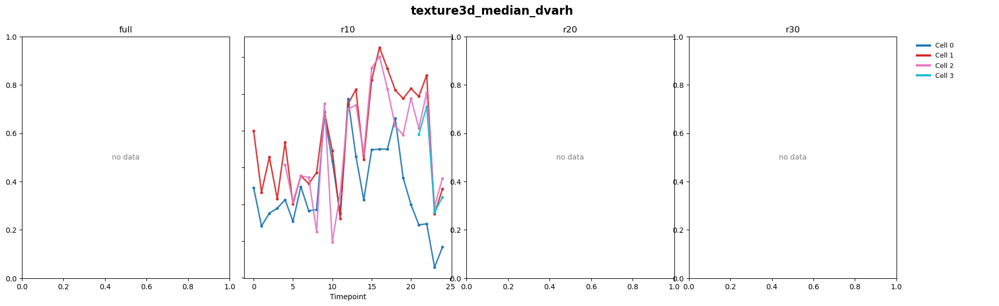

In [6]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

MASK_ORDER = ["full", "r10", "r20", "r30"]
LINESTYLES = ["-", "--", ":", "-."]

# Consistent color per cell across all plots
all_cells = sorted(grouped["cell"].dropna().unique(), key=lambda x: str(x))
cell_cmap = plt.get_cmap("tab10", max(len(all_cells), 1))
cell_to_color = {cell: cell_cmap(i) for i, cell in enumerate(all_cells)}

# Distinguish position via linestyle (irrelevant if only 1 position)
positions = sorted(grouped["position"].dropna().unique())
pos_to_linestyle = {pos: LINESTYLES[i % len(LINESTYLES)] for i, pos in enumerate(positions)}

EXCLUDE_PREFIXES = ("std_",)
features_to_plot = [
    f for f in grouped["feature"].unique()
    if not f.startswith(EXCLUDE_PREFIXES)
]

for feat in features_to_plot:
    subset = grouped[grouped["feature"] == feat].copy()

    fig = plt.figure(figsize=(24, 6))
    gridnum = len(MASK_ORDER) + 1  # one col per mask + legend
    gs = fig.add_gridspec(1, gridnum, width_ratios=[5] * len(MASK_ORDER) + [2], wspace=0.08)
    axes = [fig.add_subplot(gs[i]) for i in range(len(MASK_ORDER))]
    leg_ax = fig.add_subplot(gs[-1])
    leg_ax.axis("off")

    for ax_i, (ax, mask) in enumerate(zip(axes, MASK_ORDER)):
        mask_data = subset[subset["mask_type"] == mask]

        if mask_data.empty:
            ax.set_title(mask)
            ax.text(0.5, 0.5, "no data", ha="center", va="center",
                    transform=ax.transAxes, color="gray")
            continue

        for cell in all_cells:
            cell_data = mask_data[mask_data["cell"] == cell]
            if cell_data.empty:
                continue
            for pos in positions:
                line_data = cell_data[cell_data["position"] == pos].sort_values("timepoint")
                if line_data.empty:
                    continue
                ax.plot(
                    line_data["timepoint"],
                    line_data["value"],
                    color=cell_to_color[cell],
                    linestyle=pos_to_linestyle[pos],
                    linewidth=2,
                    marker="o",
                    markersize=3,
                    alpha=0.9,
                )

        ax.set_title(mask)
        ax.set_xlabel("Timepoint")
        if ax_i == 0:
            ax.set_ylabel("Value")
        else:
            ax.tick_params(labelleft=False)

    # ── Legend ───────────────────────────────────
    cell_handles = [
        Line2D([0], [0], color=cell_to_color[c], linewidth=3, label=f"Cell {c}")
        for c in all_cells
    ]
    pos_handles = [
        Line2D([0], [0], color="black", linestyle=pos_to_linestyle[p], linewidth=2, label=f"Position {p}")
        for p in positions
    ] if len(positions) > 1 else []

    leg_ax.legend(
        handles=cell_handles + pos_handles,
        loc="upper left",
        fontsize=9,
        frameon=False,
    )

    fig.suptitle(feat, fontsize=16, fontweight="bold")
    fig.tight_layout()
    plt.show()
    plt.close(fig)